# Livrable 1 : Vulgarisation scientifique

## Écouter les sons de l'espace

Dans l'espace, le son ne se propage pas (vide). Les astres émettent des ondes radio (lumière invisible). Le radiotélescope les capte, et nous les transposons en fréquences audibles pour les analyser (sonification).

## Contexte de la mission


Un signal atypique a été détecté par le radiotélescope décimétrique de Nançay. Voici les caractéristiques de ce signal :

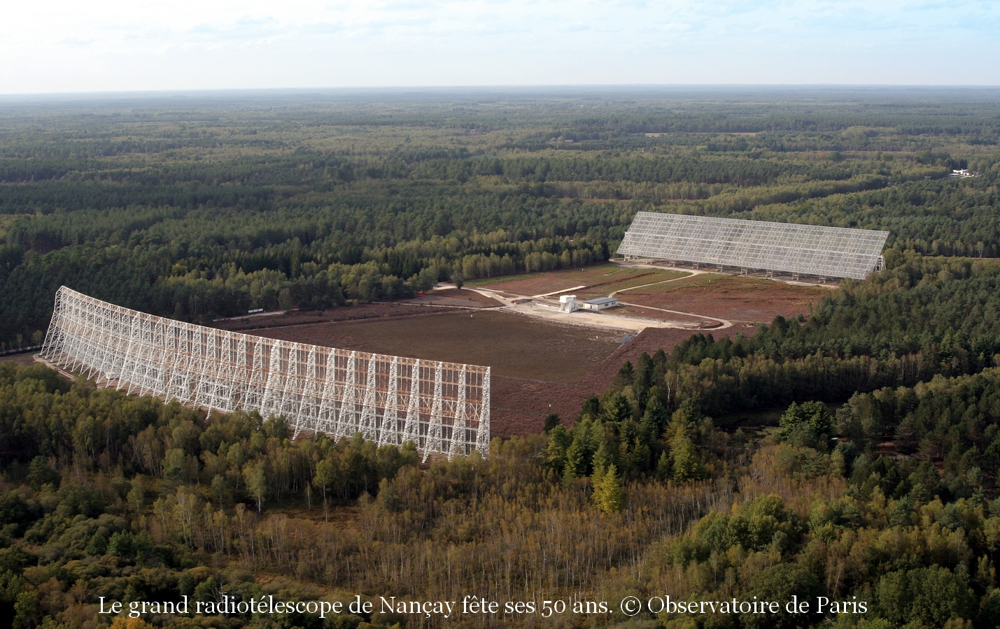
(Radiotélescope de Nançay)

-Le signal reçu se situe dans la raie des 21 cm du spectre électromagnétique, une fréquence particulièrement surveillée en radioastronomie.

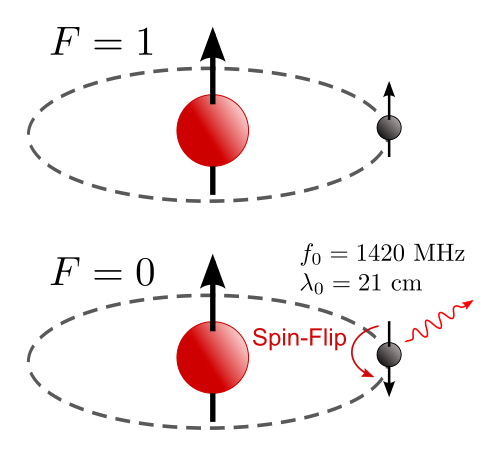

(Schéma de la transition hyperfine de l'hydrogène)
-Ce signal a été classé comme « indéterminé » par l’algorithme
-Le signal sans traitement est très bruité lors de la première écoute

## Notions scientifiques

La relation fondamentale entre la fréquence ($f$) et la longueur d'onde ($\lambda$) est donnée par l'équation :

$$f = \frac{c}{\lambda}$$

Où :
* $c \approx 299\,792\,458 \text{ m/s}$ (Vitesse de la lumière dans le vide)
* $\lambda = 0,211 \text{ m}$ (Longueur d'onde de 21 cm)

En appliquant ces valeurs, nous obtenons la fréquence de travail :

$$f \approx \frac{3 \times 10^8}{0,21} \approx 1\,420\,405\,751 \text{ Hz} \approx 1,42 \text{ GHz}$$

Or numériser directement un signal oscillant 1,4 milliard de fois par seconde demande une puissance de calcul colossale. Pour rendre le signal exploitable par nos ordinateurs, nous utilisons une technique appelée la **Translation de fréquence**.

## La Translation de Fréquence (Hétérodynage)

Pour expliquer la translation de fréquence nous pouvons utiliser l'analogie du train : maginez que le signal radio est un passager dans un train à grande vitesse (haute fréquence, 1.42 GHz). Pour l'interviewer (l'analyser), il est difficile de courir aussi vite que le train.
Au lieu de courir, nous faisons monter le passager dans un train plus lent qui roule sur une voie parallèle, tout en gardant exactement les mêmes vêtements et valises (l'information du signal).

L'équation pour réaliser cette translation est donc :

$$f_{FI} = | f_{RF} - f_{LO} |$$

Nous mélangeons le signal reçu ($f_{RF}$) avec un signal local de référence ($f_{LO}$). Nous gardons que la différence de ce mélange.

Grâce à cette opération, le signal de 1,42 GHz est abaissé à une fréquence audible ou facilement numérisable (quelques kHz ou MHz), sans perdre son contenu informatif.

## Chaine d'Acquisition du son de l'espace 

```mermaid
graph TD
    classDef space fill:#2b2b2b,stroke:#fff,stroke-width:2px,color:#fff;
    classDef analog fill:#fff3e0,stroke:#e65100,stroke-width:2px,color:#000;
    classDef digital fill:#e8f5e9,stroke:#2e7d32,stroke-width:2px,color:#000;
    classDef acoustic fill:#e1f5fe,stroke:#0277bd,stroke-width:2px,color:#000;

    Source("Source Inconnue"):::space
    Antenne("Radiotélescope de Nançay<br/>Miroir + Antenne"):::analog
    LNA("Amplificateur LNA<br/>& Mélangeur"):::analog
    ADC("Convertisseur A/N<br/>Numérisation"):::digital
    Ordi("Ordinateur & Algo<br/>Sonification Brute"):::digital
    DAC("Carte Son / DAC"):::acoustic
    HP("Haut-Parleur"):::acoustic
    Humain("Oreille Analyste"):::acoustic

    Source -->|Onde Électromagnétique<br/>λ = 21 cm / f = 1.42 GHz| Antenne
    Antenne -->|Tension Électrique Analogique<br/>Oscillation à 1.42 GHz| LNA
    LNA -->|Signal Électrique Analogique<br/>Fréquence Intermédiaire abaissée| ADC
    ADC -->|"Flux de Bits<br/>Données brutes & bruitées"| Ordi
    Ordi -->|Fichier Audio Numérique<br/>Transposition spectrale| DAC
    DAC -->|Signal Électrique Audio<br/>20 Hz - 20 kHz| HP
    HP -->|Onde Mécanique<br/>Vibration de l'air| Humain
```

## Chaine d'Acquisition alternative avec filtre analogique

```mermaid
graph TD
    classDef space fill:#2b2b2b,stroke:#fff,stroke-width:2px,color:#fff;
    classDef analog fill:#fff3e0,stroke:#e65100,stroke-width:2px,color:#000;
    classDef filterAna fill:#ffccbc,stroke:#d84315,stroke-width:3px,color:#000;
    classDef digital fill:#e8f5e9,stroke:#2e7d32,stroke-width:2px,color:#000;
    classDef filterNum fill:#c8e6c9,stroke:#1b5e20,stroke-width:3px,color:#000;
    classDef output fill:#e1f5fe,stroke:#0277bd,stroke-width:2px,color:#000;

    Source("Source Inconnue"):::space
    Antenne("Radiotélescope"):::analog
    LNA("LNA & Mélangeur"):::analog
    FiltreA("FILTRE ANALOGIQUE<br/>(Passe-Bande)"):::filterAna
    ADC("Convertisseur A/N"):::digital
    FiltreN("FILTRE NUMÉRIQUE<br/>(Denoising / FFT)"):::filterNum
    Visu("Analyse Spectrale<br/>(Python)"):::output

    Source -->|Onde Électromagnétique| Antenne
    Antenne -->|Signal Électrique| LNA
    LNA -->|Signal Bruité/Large bande| FiltreA
    FiltreA -->|Signal Nettoyé/Bande étroite| ADC
    ADC -->|Données Brutes| FiltreN
    FiltreN -->|Données Traitées| Visu  
```

## Analyse Numérique du Signal

Nous procédons maintenant à l'analyse du fichier `signal_recu_transpose (1).wav`.

1.  **La FFT (Fast Fourier Transform) :** Elle nous permet de passer du domaine temporel (forme de l'onde) au domaine fréquentiel (quelles sont les notes qui composent le signal).
2.  **Le Spectrogramme :** C'est une représentation 3D (Temps, Fréquence, Intensité) indispensable pour repérer des signaux qui évoluent dans le temps (comme un "bip" qui changerait de ton), souvent signe d'une origine technologique.

Fichier chargé avec succès : signal_recu_transpose (1).wav
Fréquence d'échantillonnage : 44100 Hz
Durée du signal : 12.80 secondes
Fréquence dominante trouvée : 1450.00 Hz


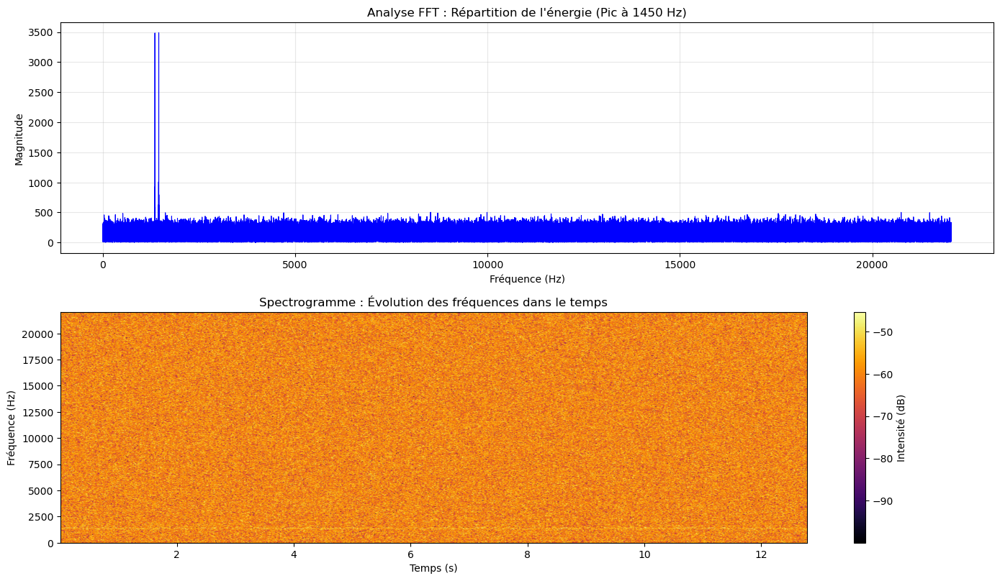

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import spectrogram

filename = 'signal_recu_transpose (1).wav'

try:
    # Lecture du fichier WAV
    fs, data = wavfile.read(filename)
    
    # Normalisation du signal
    if np.issubdtype(data.dtype, np.integer):
        max_val = np.iinfo(data.dtype).max
        signal_received = data / max_val
    else:
        signal_received = data

    print(f"Fichier chargé avec succès : {filename}")
    print(f"Fréquence d'échantillonnage : {fs} Hz")
    print(f"Durée du signal : {len(signal_received)/fs:.2f} secondes")

    # Création de l'axe temporel
    n = len(signal_received)
    t = np.linspace(0, n / fs, n, endpoint=False)

    # ANALYSE FFT (Transformation de Fourier)
    fft_values = np.fft.fft(signal_received)
    fft_magnitude = np.abs(fft_values)
    freqs = np.fft.fftfreq(n, 1/fs)

    # AJOUT : CALCUL DE LA FRÉQUENCE DOMINANTE
    mask = freqs > 0 # On garde les fréquences positives (> 0 Hz)
    
    # On cherche l'index où la magnitude est maximale dans ces fréquences
    idx_max = np.argmax(fft_magnitude[mask])
    frequence_dominante = freqs[mask][idx_max]
    
    print(f"Fréquence dominante trouvée : {frequence_dominante:.2f} Hz")

    # AFFICHAGE DES RÉSULTATS
    plt.figure(figsize=(14, 12))

    # Graphique de la FFT 
    plt.subplot(3, 1, 2)
    # Utilisation du masque défini plus haut
    plt.plot(freqs[mask], fft_magnitude[mask], color='blue', linewidth=0.8)
    plt.title(f"Analyse FFT : Répartition de l'énergie (Pic à {frequence_dominante:.0f} Hz)")
    plt.xlabel("Fréquence (Hz)")
    plt.ylabel("Magnitude")
    plt.xscale('linear')
    plt.grid(True, alpha=0.3)

    # Graphique du Spectrogramme 
    plt.subplot(3, 1, 3)
    f, t_spec, Sxx = spectrogram(signal_received, fs, nperseg=1024, noverlap=512)
    
    plt.pcolormesh(t_spec, f, 10 * np.log10(Sxx + 1e-10), shading='gouraud', cmap='inferno')
    plt.title("Spectrogramme : Évolution des fréquences dans le temps")
    plt.ylabel("Fréquence (Hz)")
    plt.xlabel("Temps (s)")
    plt.colorbar(label='Intensité (dB)')
    
    plt.tight_layout()
    plt.show()

except FileNotFoundError:
    print(f"ERREUR : Le fichier '{filename}' est introuvable.")
    print("Veuillez vérifier qu'il est bien dans le même dossier que ce Notebook.")
except Exception as e:
    print(f"Une erreur est survenue : {e}")

# Livrable 2 : Étude de la réponse fréquentielle et filtrage

## Étude théorique

Il y a un pic très dominant dans les très basses fréquences à 1450 Hz. Et un deuxième pic à 1350 Hz, c'est pourquoi $f_0$ sera défini à 1400 Hz.

En dehors de ce pic, le reste du spectre ressemble surtout à du bruit de fond, sans structure marquée.

La bande utile principale à conserver est d'environ 1300 Hz – 1500 Hz.

La fréquence à filtrer est en dessous de 1300 et au-dessus d'environ 1500 Hz, ce qui est principalement que du bruit.

Il faut donc utiliser un filtre passe-bande

### Modélisation Mathématique du Filtre RLC

Pour isoler la fréquence de la raie cible, nous modélisons un filtre passe-bande RLC série.
La fonction de transfert $\underline{H}(j\omega)$ est définie par :

$$ \underline{H}(j\omega) = \frac{V_{out}}{V_{in}} = \frac{j \frac{\omega}{\omega_0} \frac{1}{Q}}{1 + j \frac{\omega}{\omega_0} \frac{1}{Q} - (\frac{\omega}{\omega_0})^2} $$

Avec :
* **Pulsation propre :** $\omega_0 = \frac{1}{\sqrt{LC}}$
* **Facteur de qualité :** $Q = \frac{L\omega_0}{R}$

L'inductance $L$ est calculée pour accorder le filtre exactement sur $f_0 = 1450$ Hz :
$$ L = \frac{1}{C \cdot (2\pi f_0)^2} $$

RÉSULTATS DE LA SIMULATION
Fréquence centrale : 1400.0 Hz
Bande passante : 200 Hz (Cible : 1300-1500 Hz)
Composants : R = 16.24 Ohm, L = 0.01292 H, C = 1.0 µF


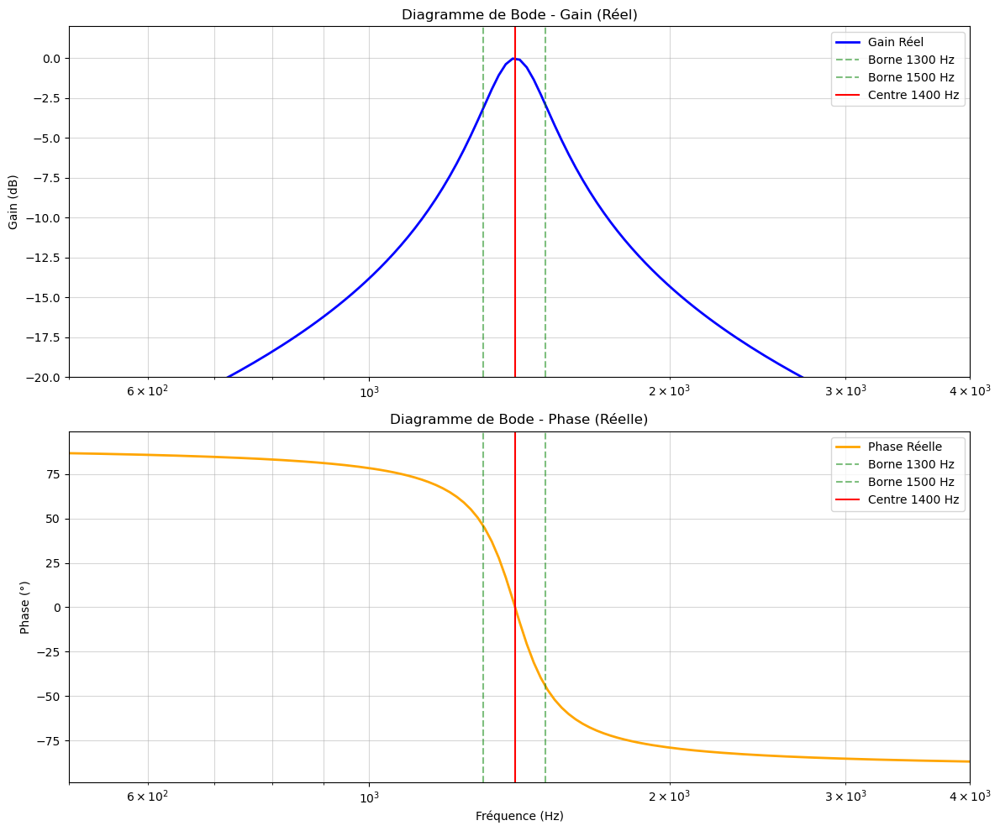

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# PARAMÈTRES (Cible 1300-1500 Hz)
f0 = 1400.0         # Fréquence centrale
w0 = 2 * np.pi * f0 
bandwidth = 1500 -1300 # Bande passante = 200 Hz
Q = f0 / bandwidth     # Q = 7

# Composants (C = 1uF pour avoir des valeurs réalistes)
C = 1e-6           
L = 1 / (C * w0**2)
R = (L * w0) / Q 

print(f"RÉSULTATS DE LA SIMULATION")
print(f"Fréquence centrale : {f0} Hz")
print(f"Bande passante : {f0/Q:.0f} Hz (Cible : 1300-1500 Hz)")
print(f"Composants : R = {R:.2f} Ohm, L = {L:.5f} H, C = {C*1e6:.1f} µF")

# FONCTION DE TRANSFERT 
num = [w0/Q, 0]
den = [1, w0/Q, w0**2]
system = signal.TransferFunction(num, den)

#  DIAGRAMME DE BODE (RÉEL) 
w, mag, phase = signal.bode(system, n=1000)
freqs_hz = w / (2 * np.pi)

plt.figure(figsize=(12, 10))

# Graphique du GAIN
plt.subplot(2, 1, 1)
plt.semilogx(freqs_hz, mag, color='blue', linewidth=2, label='Gain Réel')
# Marqueurs du Gain
plt.axvline(x=1300, color='green', linestyle='--', alpha=0.5, label='Borne 1300 Hz')
plt.axvline(x=1500, color='green', linestyle='--', alpha=0.5, label='Borne 1500 Hz')
plt.axvline(x=f0, color='red', linestyle='-', label=f'Centre {f0:.0f} Hz')

plt.title(f"Diagramme de Bode - Gain (Réel)")
plt.ylabel("Gain (dB)")
plt.legend()
plt.grid(True, which="both", alpha=0.5)
plt.xlim(500, 4000)
plt.ylim(-20, 2)

# Graphique de la PHASE
plt.subplot(2, 1, 2)
plt.semilogx(freqs_hz, phase, color='orange', linewidth=2, label='Phase Réelle')
# Marqueurs de la Phase 
plt.axvline(x=1300, color='green', linestyle='--', alpha=0.5, label='Borne 1300 Hz')
plt.axvline(x=1500, color='green', linestyle='--', alpha=0.5, label='Borne 1500 Hz')
plt.axvline(x=f0, color='red', linestyle='-', label=f'Centre {f0:.0f} Hz')

plt.xlabel("Fréquence (Hz)")
plt.ylabel("Phase (°)")
plt.title("Diagramme de Bode - Phase (Réelle)")
plt.legend()
plt.grid(True, which="both", alpha=0.5)
plt.xlim(500, 4000)

plt.tight_layout()
plt.show()

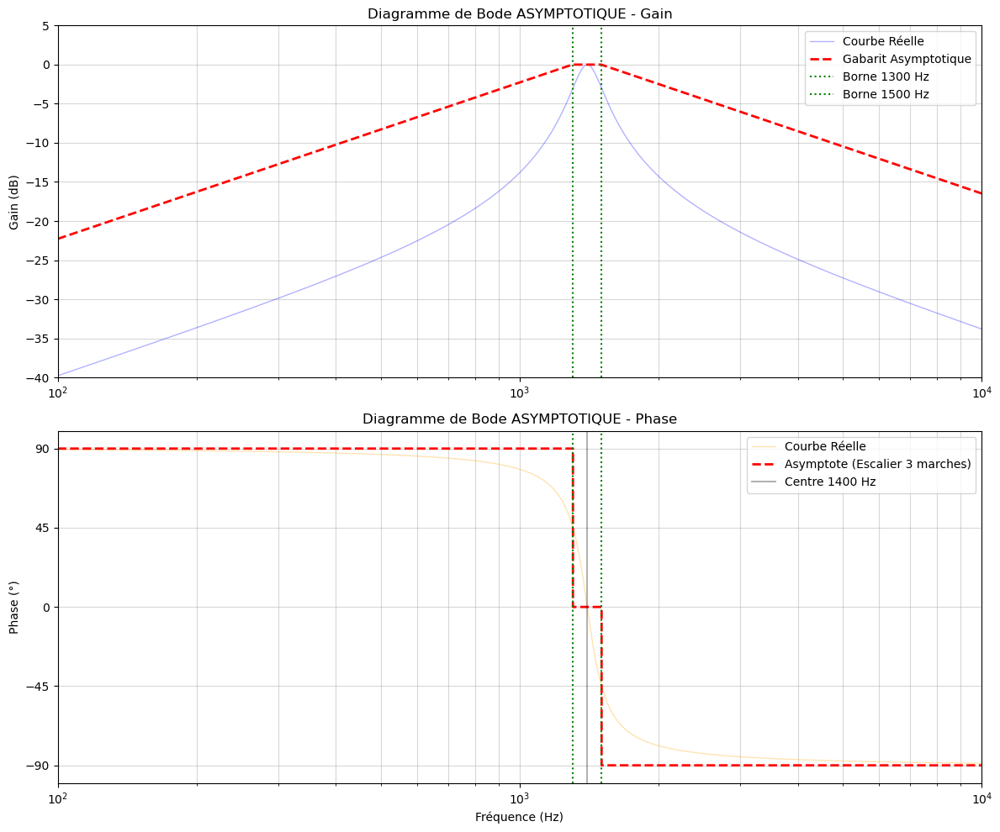

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# PARAMÈTRES
f0 = 1400.0         
fbas = 1300.0      # Début de la marge 
fhaut = 1500.0     # Fin de la marge 
w0 = 2 * np.pi * f0

# Calcul du Q pour la simulation réelle
Q = 1400 / 200 
C = 1e-6           
L = 1 / (C * w0**2)
R = (L * w0) / Q 

#  CALCUL DE LA COURBE RÉELLE (Pour le fond) 
num = [w0/Q, 0]
den = [1, w0/Q, w0**2]
system = signal.TransferFunction(num, den)
w, mag, phase = signal.bode(system, n=2000)
freqs_hz = w / (2 * np.pi)

#  CONSTRUCTION DES ASYMPTOTES 
f_asymp = np.logspace(2, 4, 1000) # De 100 à 10000 Hz

# Gain Asymptotique 
def get_asymp_gain(f):
    if f < fbas:
        return 20 * np.log10(f / fbas) 
    elif f > fhaut:
        return -20 * np.log10(f / fhaut) 
    else:
        return 0 

gain_asymp = [get_asymp_gain(f) for f in f_asymp]

# Phase Asymptotique 
def get_asymp_phase(f):
    if f < fbas:
        return 90  
    elif f > fhaut:
        return -90 
    else:
        return 0  

phase_asymp = [get_asymp_phase(f) for f in f_asymp]

#  AFFICHAGE 
plt.figure(figsize=(12, 10))

# GRAPHIQUE DU GAIN
plt.subplot(2, 1, 1)
plt.semilogx(freqs_hz, mag, color='blue', alpha=0.3, linewidth=1, label='Courbe Réelle')
plt.semilogx(f_asymp, gain_asymp, 'r--', linewidth=2, label='Gabarit Asymptotique')

# Bornes vertes
plt.axvline(x=fbas, color='green', linestyle=':', label=f'Borne {fbas:.0f} Hz')
plt.axvline(x=fhaut, color='green', linestyle=':', label=f'Borne {fhaut:.0f} Hz')

plt.title("Diagramme de Bode ASYMPTOTIQUE - Gain")
plt.ylabel("Gain (dB)")
plt.legend()
plt.grid(True, which="both", alpha=0.5)
plt.ylim(-40, 5)
plt.xlim(100, 10000)

# GRAPHIQUE DE LA PHASE 
plt.subplot(2, 1, 2)
plt.semilogx(freqs_hz, phase, color='orange', alpha=0.3, linewidth=1, label='Courbe Réelle')

# Tracé de l'escalier rouge
plt.step(f_asymp, phase_asymp, 'r--', where='post', linewidth=2, label='Asymptote (Escalier 3 marches)')

# Bornes vertes pour bien voir l'alignement
plt.axvline(x=fbas, color='green', linestyle=':')
plt.axvline(x=fhaut, color='green', linestyle=':')
plt.axvline(x=f0, color='black', linestyle='-', alpha=0.3, label=f'Centre {f0:.0f} Hz')

plt.xlabel("Fréquence (Hz)")
plt.ylabel("Phase (°)")
plt.title("Diagramme de Bode ASYMPTOTIQUE - Phase")
plt.legend()
plt.grid(True, which="both", alpha=0.5)
plt.ylim(-100, 100)
plt.yticks([-90, -45, 0, 45, 90]) 
plt.xlim(100, 10000)

plt.tight_layout()
plt.show()

### Transition vers le traitement numérique

Après avoir validé le modèle théorique du filtre passe-bande (RLC) via le diagramme de Bode ci-dessus, nous appliquons maintenant un équivalent numérique (Filtre de Butterworth) sur le signal audio réel pour en extraire l'information utile.

On agrandit légerement les bornes pour un résultat plus logique.

Fichier charge avec succes. Frequence : 44100 Hz
Filtrage applique entre 1250.0 Hz et 1550.0 Hz.


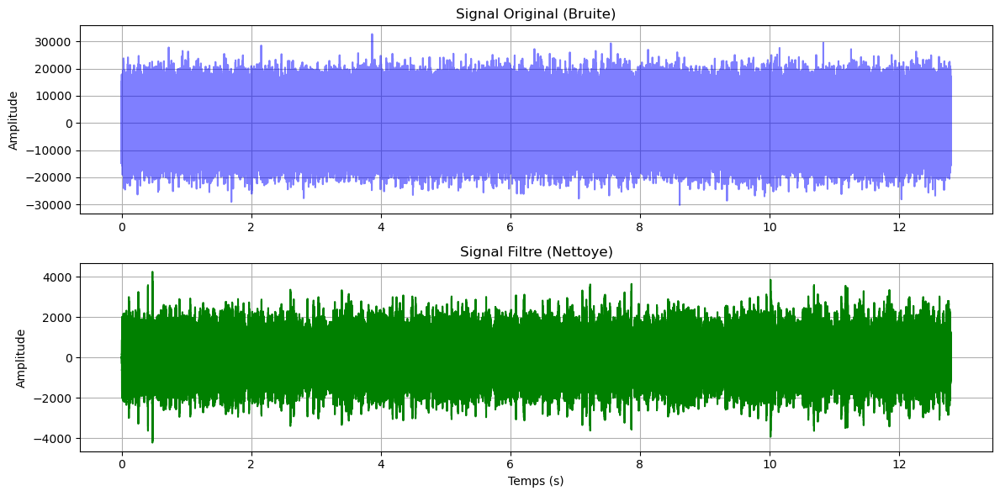

Ecoute du signal nettoye :


In [24]:
import numpy as np
import scipy.io.wavfile as wav
from scipy.signal import butter, lfilter
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Chargement du fichier
filename = "signal_recu_transpose (1).wav" 
fs, signal_received = wav.read(filename)

# Creation de l'axe temporel
duration = len(signal_received) / fs
times = np.linspace(0, duration, len(signal_received))
print(f"Fichier charge avec succes. Frequence : {fs} Hz")

# Fonctions de filtrage (Passe-bande)
def butter_bandpass(lowcut, highcut, fs, order=5):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return b, a

def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = lfilter(b, a, data)
    return y

# Application du filtre
# On conserve uniquement les frequences autour du signal utile (1400 Hz)
lowcut = 1250.0
highcut = 1550.0

signal_filtre = butter_bandpass_filter(signal_received, lowcut, highcut, fs, order=6)
print(f"Filtrage applique entre {lowcut} Hz et {highcut} Hz.")

# Affichage des resultats
plt.figure(figsize=(12, 6))

# Signal Original
plt.subplot(2, 1, 1)
plt.plot(times, signal_received, color='blue', alpha=0.5)
plt.title("Signal Original (Bruite)")
plt.ylabel("Amplitude")
plt.grid(True)

# Signal Filtre
plt.subplot(2, 1, 2)
plt.plot(times, signal_filtre, color='green')
plt.title("Signal Filtre (Nettoye)")
plt.xlabel("Temps (s)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()

# Lecture audio
print("Ecoute du signal nettoye :")
display(Audio(signal_filtre, rate=fs))

## Filtre à utiliser : Filtre RLC passe-bande

Il s'agit d'un filtre RLC passe-bande (naturellement d’ordre 2) pour isoler un son particulier et rejeter les autres bruits dont on n’a pas besoin. Le filtre passe-bande permet de faire passer une bande étroite autour de la fréquence d’intérêt $f_0$. Il atténue les basses fréquences et les hautes fréquences.

### Justification

On utilise un filtre d’ordre 2 car un filtre d’ordre 1 ne rejette pas assez les bruits (pente plus faible), comparé à un filtre d’ordre 2 qui isole bien les sons grâce à une sélectivité plus importante.

### Schéma et Composants

**Composants :** résistance ($R$), inductance ($L$) et condensateur ($C$).

On choisit un circuit **RLC en série** avec une **sortie sur la résistance**. À la résonance, l'impédance de la paire $L-C$ s'annule, le courant est maximum et la tension aux bornes de la résistance est donc maximale (proche de la tension d'entrée).

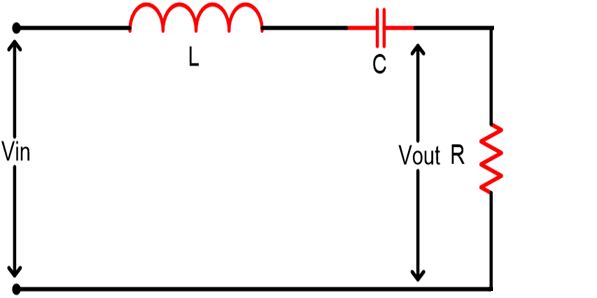
(Schéma d'un montage RLC)

### Calcul des composants

On veut centrer le filtre sur :

$$f_0 \approx 1400 \text{ Hz}$$

**Fréquence de résonance (pulsation propre) :**
Soit , définie par la relation :

$$\omega_0 = \frac{1}{\sqrt{LC}}$$ donc $$LC = \frac{1}{\omega_0^2}$$

avec $$\omega_0 = 2\pi\cdot 1400$$        $$\approx 8796 rad/s$$

**Facteur de qualité () :**
Il est défini par le rapport entre la fréquence centrale et la largeur de bande :

$$Q = \frac{f_0}{\Delta f} = \frac{1}{R} \cdot \sqrt{\frac{L}{C}}$$

Sur le graphique de la FFT de l’audio (cf. étape précédente), le pic s’étend sur une petite plage de fréquence d’environ $\Delta f = 200 \text{ Hz}$.

Il nous faut donc $\Delta f = 200 \text{ Hz}$, ce qui donne :

$$Q = \frac{1400}{200} = 7$$

**Calcul de $L$ et $R$ :**
En choisissant une valeur de $C = 0,1 \mu\text{F}$ (valeur courante dans ce domaine), on trouve un valeur de L trop grande. On prend donc $C = 10 \mu\text{F}$.

on calcule l'inductance L :

$$L = \frac{1}{\omega_0^2C} = \frac{1}{(8796)^2\cdot10\cdot10^-6} \approx 0.0012 H = 1,2mH$$

On calcule ensuite la résistance $R$ nécessaire pour obtenir le facteur de qualité souhaité :

$$R = 2\pi L f_0 = 2\pi \cdot 1.2 \cdot 1400 \approx 13194.7 m\Omega = 13,2\Omega$$


### Fonction de transfert

$Z_R = R$  
$Z_L = j \omega L$  
$Z_C = \frac{1}{j\omega C}$

Le circuit RLC choisi est en série, l’impédance totale vaut donc :

$$\underline{Z}_{tot} = Z_R + Z_L + Z_C$$

$$\underline{Z}_{tot} = R + j L \omega + \frac{1}{j C \omega}$$

En utilisant un diviseur de tension, la fonction de transfert $\underline{}(j\omega)$ avec la tension de sortie $V_out$ prise aux bornes de $R$ est :

$$T(j\omega) = \frac{V_out}{V_in} = \frac{Z_R}{\underline{Z}_{tot}} = \frac{R}{R + j L \omega + \frac{1}{j C \omega}} = \frac{j \omega R C}{1 + j \omega R C - \omega^2 L C}$$

Avec $\omega_0 = \frac{1}{\sqrt{LC}}$ et $LC = \frac{1}{\omega_0^2}$ et $Q = \frac{1}{R}\sqrt{\frac{L}{C}}$, on met sous forme canonique :

$$\omega^2LC = \frac{\omega^2}{\omega_0^2} = (\frac{\omega}{\omega_0})^2$$

$$RC = \frac{1}{\omega_0 Q}$$  soit   $${j \omega R C} = \frac{j \omega}{\omega_0 Q}$$

En remplaçant on obtient donc : 

$$T(j\omega) = \frac{\frac{j\omega}{\omega_0 Q}}{1+\frac{j\omega}{\omega_0 Q}(\frac{\omega}{\omega_0})^2}$$

### Paramètres du filtre

* **Facteur de qualité :**

$$Q = \frac{1}{R} \sqrt{\frac{L}{C}}$$

* **Pulsation propre :**

$$\omega_0 = \frac{1}{\sqrt{LC}}$$

* **Pulsations de coupure (à -3dB) :**
Les pulsations basse  et haute  sont données par :

$$\omega_{C1,2} = \omega_0 \left( \sqrt{1 + \frac{1}{4Q^2}} \mp \frac{1}{2Q} \right)$$

Pour $Q \ge 1$, cela peut être arrondi par l'approximation symétrique :

$$\omega_{C1,2} \approx \omega_0 \mp \frac{\Delta \omega}{2}$$

**Simulation d'un filtre passe-bande sur Falstad**
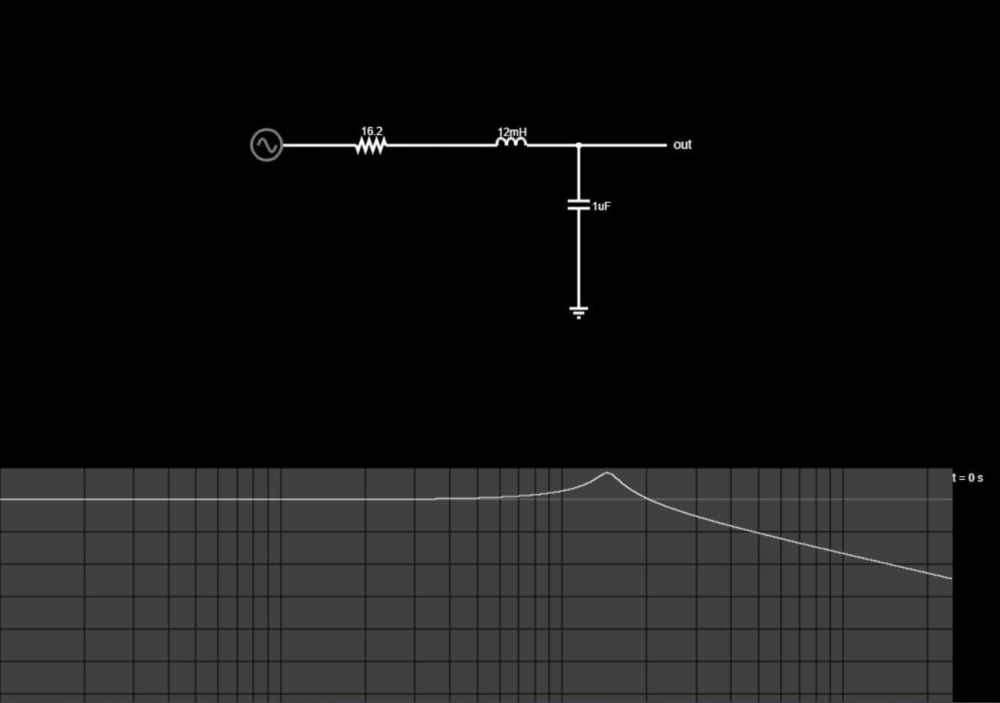
(Montage RLC sur Falstad)
On observe bien un filtre un diagramme de Bode des gains, ce montage réalise donc bien un filtre passe-bande. Nous pouvons également observer un pic à 1.43kH.
Nous pouvons donc le réaliser dans la vraie vie.

### Application : 

**Voici un montage réel d'un filtre passe bande avec des vrais composants**
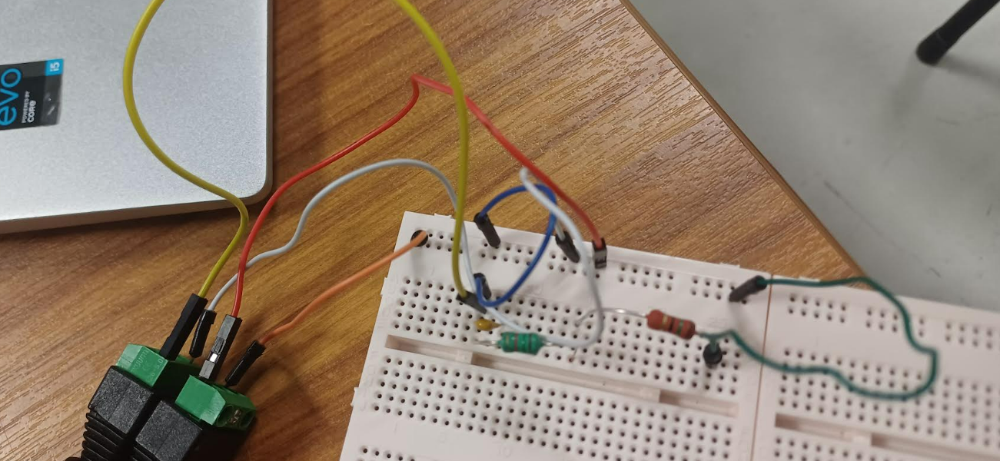

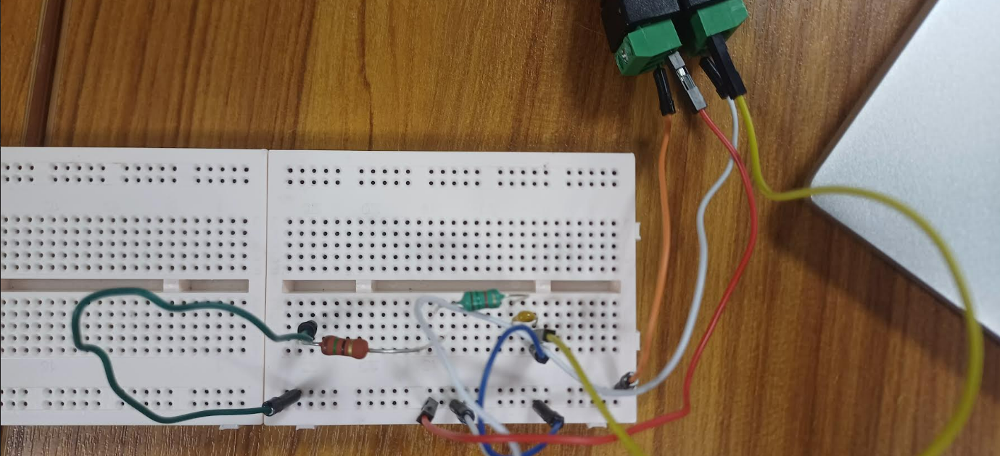

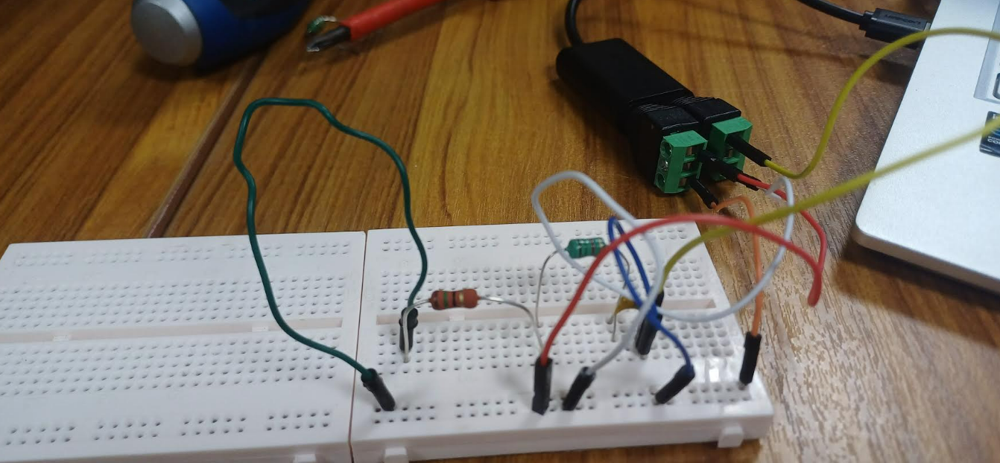


Nous avons ensuite mesuré la réponse fréquentielle du montage électronique à l'aide du logiciel AudMes : 

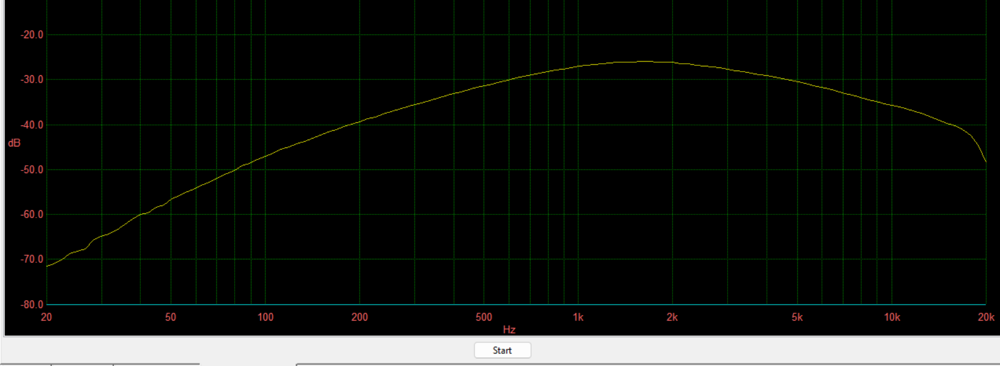
Fréquence du circuit passe-bande sans le son. 

On peut remarquer qu’il y a une atténuation des sons de 20Hz à environ 300Hz et de 5kHz à 20Kh. Il y a un pic entre 1Khz et 2,5kHz. On a donc bien un filtre passe bande

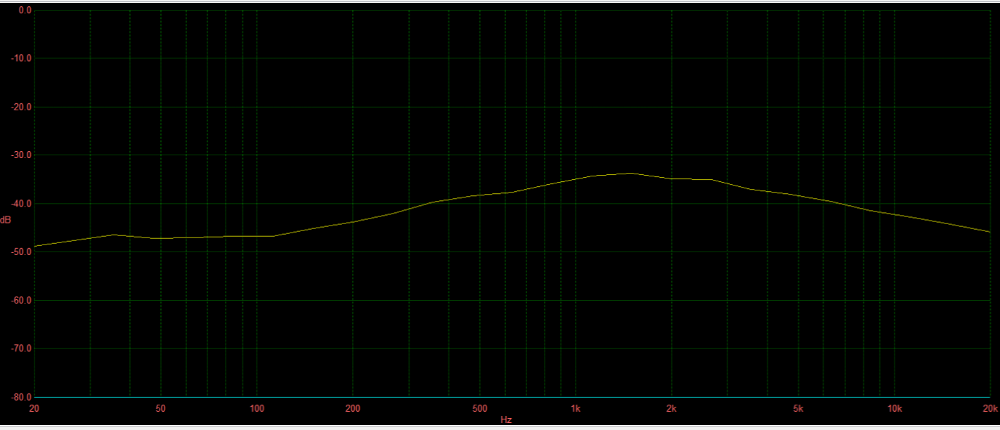
Fréquence de circuit passe-bande avec le son. 

Sur ce graphique on retrouve un pic plus marqué autour de 1kHz et 4kHz et une atténuation sur le reste de la courbe. Le filtre passe-bande atténue donc bien les sons autour d’une plage de fréquence spécifique.
D’après nos calculs, notre filtre passe-bande devait atténuer les sons sur une petite plage de fréquence d’environ Δf =200Hz, autour de nos 2 pic se situant à 1300Hz. Les fréquences marquées se situent dans notre plage de fréquence de 200Hz. Le filtre obtenu corrsespond donc bien aux attentes et concorde avec nos données.


### Diagramme de Bode : 

Le diagramme de Bode est un moyen de représenter la réponse en fréquence d'un système, notamment électronique. Il est à l’échelle semi-logarithmique ce qui permet de placer un grand intervalle de fréquences sur une échelle plus courte. 
Le diagramme de Bode est en réalité constitué de deux diagrammes : le diagramme de gain, et le diagramme de phase.


DIMENSIONNEMENT FINAL DU FILTRE RLC
Objectif : Passe-bande centré sur 1400 Hz (Marge : 1300-1500 Hz)
Facteur de Qualité : Q = 7.0
Composants calculés :
  R = 1.62 Ω
  L = 0.00129 H  (soit 1.29 mH)
  C = 10.0 µF


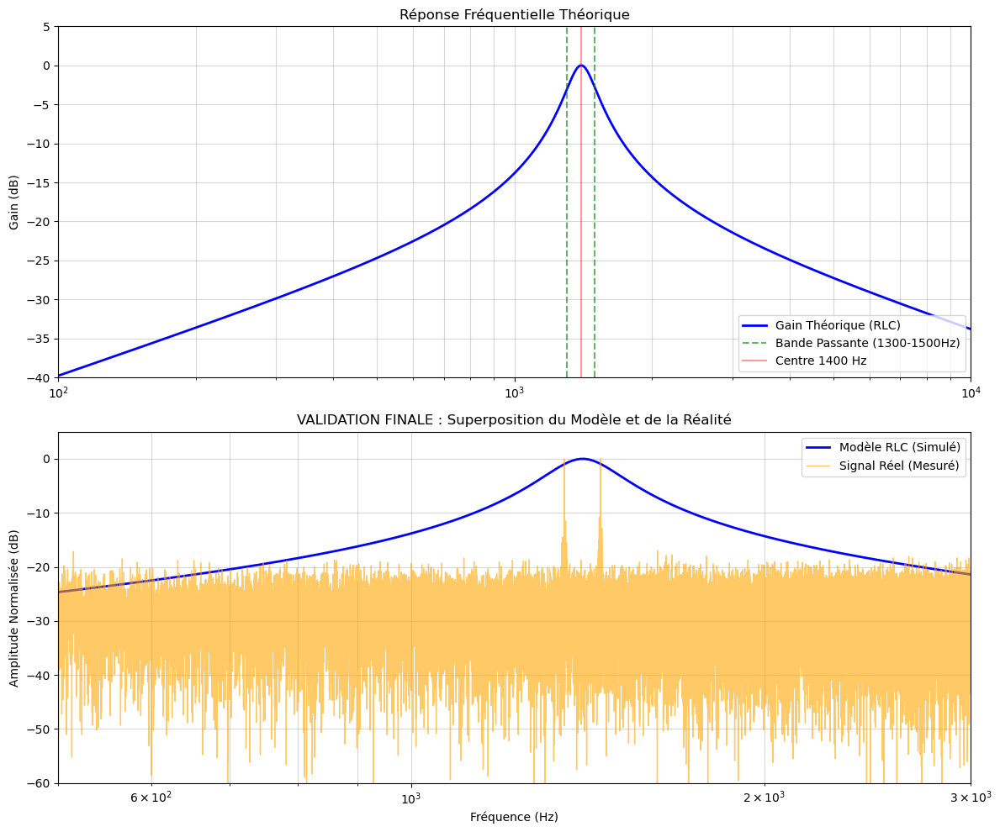

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import rfft, rfftfreq

# PARAMÈTRES 
f0 = 1400.0
w0 = 2 * np.pi * f0
Q = 7.0  
C = 10e-6  # Condensateur (1 µF)
L = 1 / (C * w0**2)
R = (L * w0) / Q

# AFFICHAGE
print("DIMENSIONNEMENT FINAL DU FILTRE RLC")
print(f"Objectif : Passe-bande centré sur {f0:.0f} Hz (Marge : 1300-1500 Hz)")
print(f"Facteur de Qualité : Q = {Q}")
print(f"Composants calculés :")
print(f"  R = {R:.2f} Ω")
print(f"  L = {L:.5f} H  (soit {L*1000:.2f} mH)")
print(f"  C = {C*1e6:.1f} µF")

# MODÉLISATION (Fonction de transfert)
num = [w0/Q, 0]
den = [1, w0/Q, w0**2]
system = signal.TransferFunction(num, den)

# PRÉPARATION DES DONNÉES

# Simulation (Bode Théorique)
w, mag, phase = signal.bode(system, n=2000)
freqs_bode = w / (2 * np.pi)

# Données Réelles (FFT du signal wav pour la validation)
try:
    yf = rfft(signal_received)
    xf = rfftfreq(len(signal_received), 1 / fs)
    # Conversion dB et Normalisation (Pic max à 0 dB) pour comparaison visuelle
    fft_db = 20 * np.log10(np.abs(yf) + 1e-12)
    fft_db_norm = fft_db - np.max(fft_db)
    has_real_data = True
except NameError:
    print("ATTENTION : Le fichier audio n'est pas chargé. Lancez la cellule de lecture WAV avant.")
    has_real_data = False

# TRACÉ DE VALIDATION 
plt.figure(figsize=(12, 10))

# Sous-graphe 1 : Le Diagramme de Bode (Gain)
plt.subplot(2, 1, 1)
plt.semilogx(freqs_bode, mag, color='blue', linewidth=2, label='Gain Théorique (RLC)')
plt.axvline(x=1300, color='green', linestyle='--', alpha=0.6, label='Bande Passante (1300-1500Hz)')
plt.axvline(x=1500, color='green', linestyle='--', alpha=0.6)
plt.axvline(x=f0, color='red', linestyle='-', alpha=0.4, label=f'Centre {f0:.0f} Hz')
plt.ylabel("Gain (dB)")
plt.title("Réponse Fréquentielle Théorique")
plt.legend(loc='lower right')
plt.grid(True, which="both", alpha=0.5)
plt.xlim(100, 10000)
plt.ylim(-40, 5)

# Sous-graphe 2 : LA PREUVE (Comparaison Réel vs Modèle)
plt.subplot(2, 1, 2)
# Courbe du Modèle (Bleue)
plt.semilogx(freqs_bode, mag, color='blue', linewidth=2, label='Modèle RLC (Simulé)')
# Courbe du Signal Réel (Orange)
if has_real_data:
    mask = xf > 0 # On ne garde que les fréquences positives
    plt.semilogx(xf[mask], fft_db_norm[mask], color='orange', alpha=0.6, linewidth=1, label='Signal Réel (Mesuré)')

plt.title("VALIDATION FINALE : Superposition du Modèle et de la Réalité")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude Normalisée (dB)")
plt.legend(loc='upper right')
plt.grid(True, which="both", alpha=0.5)
plt.xlim(500, 3000) # Zoom précis sur le pic
plt.ylim(-60, 5)

plt.tight_layout()
plt.show()

# Livrable 3 : Chaîne de transmission


### Chaîne de communication numérique AFSK

Ce notebook présente la simulation d'une chaîne de communication numérique utilisant une modulation AFSK.

```mermaid
graph TD
    subgraph Entree ["Source (Fichier Audio)"]
        A[/"Fichier .wav (Sons de l'espace)"/] -->|"Lecture"| B("Signal Numérique Brut")
    end

    subgraph Demodulation ["Démodulation FSK"]
        B -->|"Filtrage Passe-Bande"| C("Isolation du Canal")
        C -->|"Calcul Fréquence Instantanée"| D("Discriminateur de Fréquence")
        D -->|"Signal Bruité (Pics)"| E("Filtrage Passe-Bas (Lissage)")
    end

    subgraph Decision ["Décision Binaire"]
        E -->|"Signal Lissé"| F("Synchronisation (Bit Sync)")
        F -->|"Instants d'échantillonnage"| G("Comparateur (Seuil)")
        G -->|"Si > Seuil = 1, Sinon = 0"| H("Flux de Bits (0101...)")
    end

    H --> I[/"Reconstruction (Image/Texte)"/]

    style A fill:#f64,stroke:#333,stroke-width:2px
    style E fill:#f96,stroke:#333,stroke-width:4px
    style I fill:#467,stroke:#333,stroke-width:2px
```

### Filtrage du signal : 

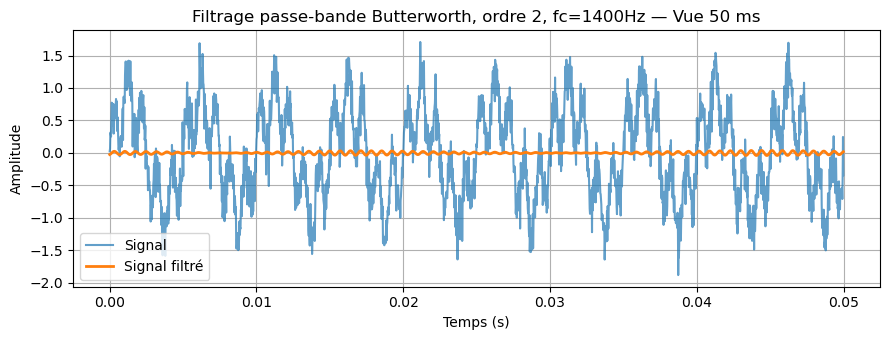

Ecoute du signal filtré :


In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

# Paramètre du signal  
Fs = 44100 # fréquence d'échantillonnage (Hz)

#Conception filtre passe-bas Butterworth  
ordre = 2
fc1 = 1350 # fréquence de coupure basse
fc2 = 1450 # fréquence de coupure haute
Wn = [fc1/(Fs/2), fc2/(Fs/2)] #normalisation des fréquences
b, a = butter(ordre, Wn, btype="band")#coeff du filtre
rng = np.random.default_rng(0) # reproductible
x = 0.8*np.sin(2*np.pi*200*t) + 0.5*np.sin(2*np.pi*1000*t) + 0.2*rng.standard_normal(t.size)

#Filtrage zéro-phase (pas de déphasage : signal aligné dans le temps avec l'originel)  
y = filtfilt(b, a, x)

# Graphique   
win = int(0.050 * Fs) # 50 ms
plt.figure(figsize=(9, 3.5))
plt.plot(t[:win], x[:win], label="Signal", alpha=0.7)
plt.plot(t[:win], y[:win], label="Signal filtré", linewidth=2)
plt.title("Filtrage passe-bande Butterworth, ordre 2, fc=1400Hz — Vue 50 ms")
plt.xlabel("Temps (s)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#Ecoute de l'audio
print("Ecoute du signal filtré :")
display(Audio(y, rate=fs))

On peut voir que le signal de base comprend de nombreux bruits. Notre signal filtré nous permet de retirer les bruits parasites comme on peut le voir sur le graphique.


### Démodulation du signal filtré :

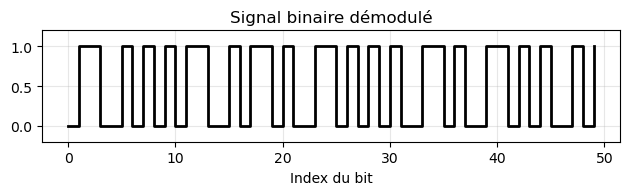

Séquence de bits extraite :
[0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0]

Signal décodé :


In [27]:
import numpy as np
import scipy.signal as signal_proc
import matplotlib.pyplot as plt
from IPython.display import Audio

# DÉMODULATION EN FSK:
samples_per_bit = 4410 # Ajustement du débit binaire : 4410 échantillons par bit (soit 10 bits/seconde à 44100Hz)
n_bits = len(signal_filtre) // samples_per_bit # calcul combien de nombre de bits on peut tenir dans la durée totale du signal

bits_extraits = []
energies_f1 = []
energies_f2 = []

f_mark = 1450  # Fréquence pour le bit '1'
f_space = 1350 # Fréquence pour le bit '0'

for i in range(n_bits):
    segment = signal_filtre[i*samples_per_bit : (i+1)*samples_per_bit]
    
    # Création de la base de temps pour le segment
    t_segment = np.arange(len(segment)) / Fs
    
    # Corrélation complexe pour extraire la magnitude aux fréquences mark/space
    ref_mark = np.exp(2j * np.pi * f_mark * t_segment)
    ref_space = np.exp(2j * np.pi * f_space * t_segment)
    
    val_mark = np.abs(np.sum(segment * ref_mark))
    val_space = np.abs(np.sum(segment * ref_space))
    
    energies_f1.append(val_mark)
    energies_f2.append(val_space)
    
    # Décision binaire
    bits_extraits.append(1 if val_mark > val_space else 0)


# Binaire : 
plt.subplot(3, 1, 3)
plt.step(range(len(bits_extraits[:50])), bits_extraits[:50], where='post', color='black', linewidth=2)
plt.ylim(-0.2, 1.2)
plt.title("Signal binaire démodulé")
plt.xlabel("Index du bit")  
plt.grid(True, alpha=0.3)
 
plt.tight_layout()
plt.show()
 
print("Séquence de bits extraite :")
print(f"{bits_extraits}")


# Ecoute de audio
print("\nSignal décodé :")
Fs = 44100  # Fréquence d'échantillonnage
t_bit = np.arange(samples_per_bit) / Fs
audio_segments = []

# Synthèse du signal
for bit in bits_extraits:
    # On choisit la fréquence selon la valeur du bit
    freq = f_mark if bit == 1 else f_space
    # Génération de la sinusoïde pour la durée d'un bit
    segment = np.sin(2 * np.pi * freq * t_bit)
    audio_segments.append(segment)

# Assemblage des segments en un seul tableau numpy
audio_reconstruit = np.concatenate(audio_segments)

display(Audio(audio_reconstruit, rate=Fs))

On obtient ici une suite de bits. Pour qu'elle ait un sens, nous devons déterminer comment elle est organisée. Afin d'obtenir le message en binaire nous avons décodé en Manchester.

### Décodage en Manchester : 

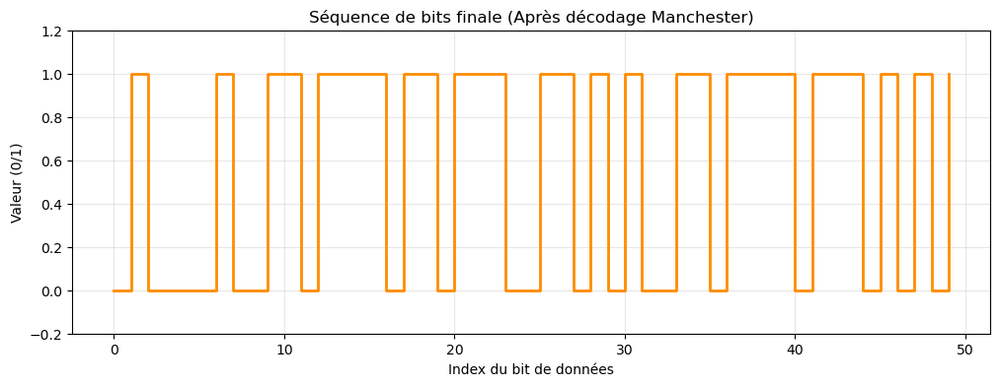

Signal binaire (longueur de 64) :
[0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1]


In [28]:
import numpy as np
import scipy.signal as signal_proc
import matplotlib.pyplot as plt
from IPython.display import Audio

# DÉCODAGE MANCHESTER:
def decode_manchester(bits):
    manchester_bits = []
    # Analyse par paires (Transition)
    for i in range(0, len(bits) - 1, 2):# mettre les bits en pair
        pair = bits[i:i+2]
        if pair == [0, 1]:    # Transition montante du signal renvoi 0
            manchester_bits.append(0)
        elif pair == [1, 0]:  # Transition descendante du signal renvoi 1 
            manchester_bits.append(1)
        # On ignore les erreurs [0,0] ou [1,1] pour la stabilité
    return manchester_bits
    
# Application du décodage: traiter les bits par pair
bits_manchester = decode_manchester(bits_extraits)
 
 
 
# Graphique
plt.figure(figsize=(12, 4))
plt.step(range(len(bits_manchester[:50])), bits_manchester[:50], where='post', color='darkorange', linewidth=2)
plt.ylim(-0.2, 1.2)
plt.title("Séquence de bits finale (Après décodage Manchester)")
plt.xlabel("Index du bit de données")
plt.ylabel("Valeur (0/1)")
plt.grid(True, alpha=0.3)
plt.show()
print(f"Signal binaire (longueur de {len(bits_manchester)}) :")
print(bits_manchester)


On obtient ici un résultat en binaire. Pour pouvoir obtenir le message il faut transformer la suite d'octets bianire en texte. Nous avons donc désencodé en UTF-8.

### Désencodage en UTF-8 pour convertir le signal binaire en texte et obtenir le message caché : 

In [29]:
# DESENCODAGE EN UTF-8:
# Convertir le signal binaire en texte
def manchester_to_utf8(bits):
    # Regroupement des bits par 8 pour former des octets (bytes)
    byte_list = []
    for i in range(0, len(bits) - 7, 8):
        # On extrait un groupe de 8 bits
        octet_bits = bits[i:i+8]
        # Conversion de la liste de bits [0, 1, 0...] en entier (base 2)
        valeur_octet = int("".join(map(str, octet_bits)), 2)# la fonction map permet d'appliquer une fonction à chaque élément d'un itérable ( ex:liste) 
        #ici, map transforme les nombres en texte (string), join les rassemble et string (str) converti le binaire en base de 10 (<10)
        byte_list.append(valeur_octet)
   
    # Conversion de la liste d'entiers en objet 'bytes' Python
    donnees_binaires = bytes(byte_list)

    # Décodage en UTF-8
    try:
        # errors='ignore' fait en sorte d'ignorer les bits/octets qui ne correspondent pas à des caractères valides.
        message = donnees_binaires.decode('utf-8', errors='ignore') #append.utf-8 permet d'associer chaque nombre à sa lettre correspondante
        return message
    except Exception as e:
        return f"[Erreur de décodage] : {e}"
 
# Exécution du désencodage : 
message_final = manchester_to_utf8(bits_manchester)

print() 
print(f"Message caché: {message_final}")


Message caché: Bonjour!



### Message final : 

On obtient donc le message caché qu'on cherchait à déterminer : "Bonjour!"
Il s'agit d'un message codé en UTF-8. Il est composé de 8 octets, c'est à dire de 64 bites. 

# Livrable 4 : Modélisation numérique

Après avoir reçu le message, nous pouvons renvoyer une réponse en effectuant toutes les étapes du livrable 3 dans le sens inverse : encodage -> codage -> modulation. Comme le message reçu n'est pas hostile, nous pouvons tout simplement lui répondre par : 'salut' ou 'coucou'.

In [30]:
message = 'Salut !'

## Passage en binaire

In [31]:
# Fonction 
def utf8_bytes(text: str) -> bytes:
    return text.encode('utf-8')

#  UTF-8
p = utf8_bytes(message)
print(f"Message: {p}")

Message: b'Salut !'


## Chiffrement XOR

In [32]:
# Définition de la clé 
key = 0x3C # Clé XOR
k = key

# Fonctions
def xor_bytes(data: bytes, key: int) -> bytes:
    return bytes(b ^ key for b in data)

# XOR
c = xor_bytes(p, k)
print(f"Clé: {k}")
print(f"Chiffre {c}")
print(f"Chiffré: {c.hex().upper()}")

Clé: 60
Chiffre b'o]PIH\x1c\x1d'
Chiffré: 6F5D5049481C1D


## Codage Manchester

Manchester: 0110100110101010011001101010011001100110010101010110010110010110011001011001010101010110101001010101011010100110


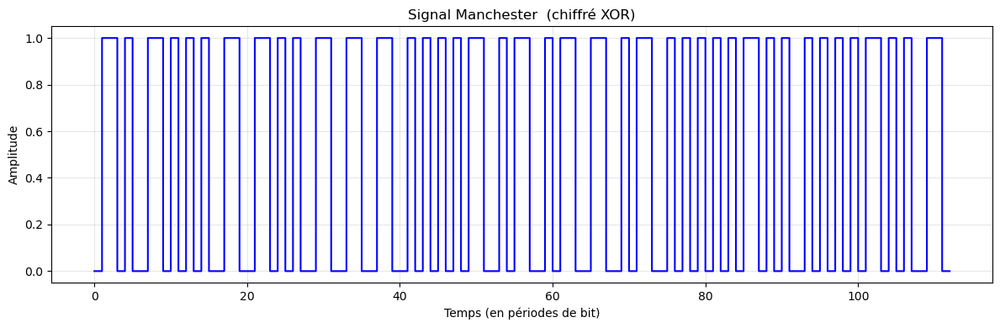

In [33]:
sps= 64

# Conversion bytes en bits
def bits_from_bytes(data: bytes) -> str:
    return ''.join(f"{byte:08b}" for byte in data)

# Manchester encoder
def manchester_encode(bits: str) -> str:
    validate_bits(bits)
    encoded_bits = []
    for bit in bits:
        # Standard IEEE 802.3 : '0' -> '01' (montant), '1' -> '10' (descendant)
        if bit == '0':
            encoded_bits.append('01')
        else:
            encoded_bits.append('10')
    return ''.join(encoded_bits)

# Vérification de la validité d'une chaîne de bits
def validate_bits(bits: str) -> str:
    if not all(b in '01' for b in bits):
        raise ValueError("La chaîne doit ne contenir que des '0' et des '1'")
    return bits

# Manchester
bits = bits_from_bytes(c)
mbits = manchester_encode(bits)
print(f"Manchester: {mbits}")

# Graphique

t = np.arange(len(mbits)*sps)/sps
x = np.zeros(len(t))

for i, bit in enumerate(mbits):
    level = 1.0 if bit == '1' else 0.0
    x[i*sps:(i+1)*sps] = level

plt.figure(figsize=(12, 4))
plt.step(t, x, where='post', color='blue', linewidth=1.5)
plt.title(f"Signal Manchester  (chiffré XOR)")
plt.xlabel("Temps (en périodes de bit)")
plt.ylabel("Amplitude")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Vérification


In [34]:
# Conversion bits en bytes
def bytes_from_bits(bits: str) -> bytes:
    if len(bits) % 8 != 0:
        raise ValueError("Le nombre de bits doit être un multiple de 8")
    byte_array = bytearray()
    for i in range(0, len(bits), 8):
        byte = bits[i:i+8]
        byte_array.append(int(byte, 2))
    return bytes(byte_array)

# Manchester decoder
def manchester_decode(manchester_bits: str) -> str:
    if len(manchester_bits) % 2 != 0:
        raise ValueError("Le nombre de bits Manchester doit être pair")
    decoded_bits = []
    for i in range(0, len(manchester_bits), 2):
        pair = manchester_bits[i:i+2]
        if pair == '01':
            decoded_bits.append('0')
        elif pair == '10':
            decoded_bits.append('1')
        else:
            raise ValueError("Invalid Manchester code")
    return ''.join(decoded_bits)

 # Vérification 
bits_back = manchester_decode(mbits)
c_back = bytes_from_bits(bits_back)
p_back = xor_bytes(c_back, key)
    
assert p_back == p
print(f"Pipeline OK — signal retrouvé: {p_back.decode()}")

Pipeline OK — signal retrouvé: Salut !


## Modulation FSK

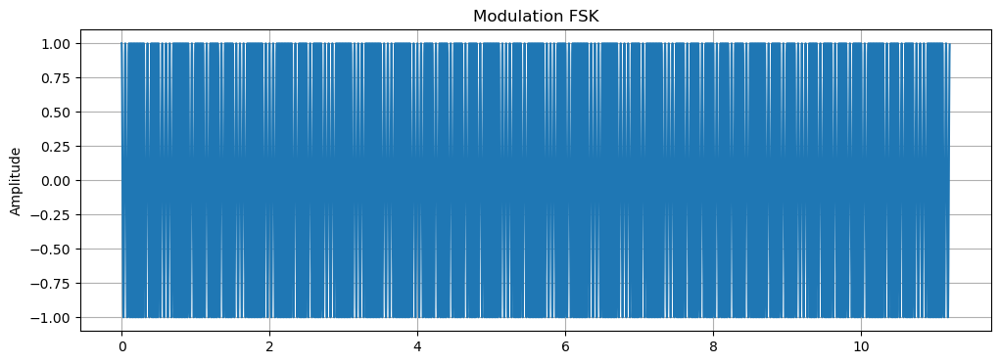

In [35]:
# Paramètres de simulation 
fe = 1000  # Définit la fréquence d'échantillonnage 
bit_rate = 10  # Débit binaire
sps = fe // bit_rate  # Echantillons par symbole (bit)
f0, f1 = 20, 50  # Fréquences FSK 

# Simulation du message Manchester 
t = np.arange(len(mbits) * sps) / fe
s_fsk = np.zeros_like(t)

# Génération du signal FSK
for i, bit in enumerate(mbits):
    idx = slice(i * sps, (i + 1) * sps)
    ti = t[idx]
    
    # FSK
    freq = f1 if bit == '1' else f0
    s_fsk[idx] = np.cos(2 * np.pi * freq * ti)

# Visualisation
plt.figure(figsize=(12, 4))
plt.plot(t, s_fsk)
plt.title("Modulation FSK")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()



## Transformation en onde sonore

In [36]:
# Paramètres
fe_audio = 44100 # Fréquence audio
sps_audio = fe_audio // 10  # 10 bits/s

# Signal FSK allongé
t_audio = np.arange(len(mbits) * sps_audio) / fe_audio
s_fsk_audio = np.zeros_like(t_audio)

f0_audio, f1_audio = 880, 1760  # La (440Hz * 2) et La (octave supérieure)

for i, bit in enumerate(mbits):
    idx = slice(i * sps_audio, (i + 1) * sps_audio)
    freq = f1_audio if bit == '1' else f0_audio
    s_fsk_audio[idx] = np.cos(2 * np.pi * freq * t_audio[idx])



# 3. Normalisation et conversion en entiers 16 bits (format WAV standard)
# On réduit un peu l'amplitude (0.5) pour éviter de saturer vos oreilles
audio_data = (s_fsk_audio * 0.5 * 32767).astype(np.int16)

# 4. Sauvegarde et écoute
wavfile.write("signal_fsk.wav", fe_audio, audio_data)
print("Signal :  ")
display(Audio("signal_fsk.wav"))


Signal :  


## Pour bien être sûr d'avoir envoyé un signal, on effectue toute la démarche en sens inverse en réutilisant nos codes pour le signal reçu : démodulation -> décodage -> désencodage -> déchiffrement 

## Démodulation

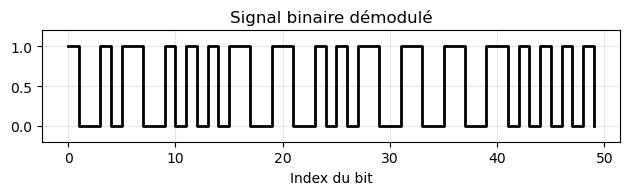

Séquence de bits extraite :
[1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1]

Signal décodé :


In [37]:
import numpy as np
import scipy.signal as signal_proc
import matplotlib.pyplot as plt
from IPython.display import Audio
import scipy.io.wavfile as wav

# Chargement du fichier
name = ("signal_fsk.wav")
fs, signal_envoyé = wav.read(name)

# DÉMODULATION EN FSK:
samples_per_bit = 4410 # Ajustement du débit binaire : 4410 échantillons par bit (soit 10 bits/seconde à 44100Hz)
n_bits = len(signal_envoyé) // samples_per_bit # calcul combien de nombre de bits on peut tenir dans la durée totale du signal

bits_extraits = []
energies_f1 = []
energies_f2 = []

f_mark = 880  # Fréquence pour le bit '1'
f_space = 1760 # Fréquence pour le bit '0'

for i in range(n_bits):
    segment = signal_envoyé[i*samples_per_bit : (i+1)*samples_per_bit]
    
    # Création de la base de temps pour le segment
    t_segment = np.arange(len(segment)) / fs
    
    # Corrélation complexe pour extraire la magnitude aux fréquences mark/space
    ref_mark = np.exp(2j * np.pi * f_mark * t_segment)
    ref_space = np.exp(2j * np.pi * f_space * t_segment)
    
    val_mark = np.abs(np.sum(segment * ref_mark))
    val_space = np.abs(np.sum(segment * ref_space))
    
    energies_f1.append(val_mark)
    energies_f2.append(val_space)
    
    # Décision binaire
    bits_extraits.append(1 if val_mark > val_space else 0)


# Binaire : 
plt.subplot(3, 1, 3)
plt.step(range(len(bits_extraits[:50])), bits_extraits[:50], where='post', color='black', linewidth=2)
plt.ylim(-0.2, 1.2)
plt.title("Signal binaire démodulé")
plt.xlabel("Index du bit")  
plt.grid(True, alpha=0.3)
 
plt.tight_layout()
plt.show()
 
print("Séquence de bits extraite :")
print(f"{bits_extraits}")


# Ecoute de audio
print("\nSignal décodé :")
Fs = 44100  # Fréquence d'échantillonnage
t_bit = np.arange(samples_per_bit) / fs
audio_segments = []

# Synthèse du signal
for bit in bits_extraits:
    # On choisit la fréquence selon la valeur du bit
    freq = f_mark if bit == 1 else f_space
    # Génération de la sinusoïde pour la durée d'un bit
    segment = np.sin(2 * np.pi * freq * t_bit)
    audio_segments.append(segment)

# Assemblage des segments en un seul tableau numpy
audio_reconstruit = np.concatenate(audio_segments)

display(Audio(audio_reconstruit, rate=fs))

## Décodage 

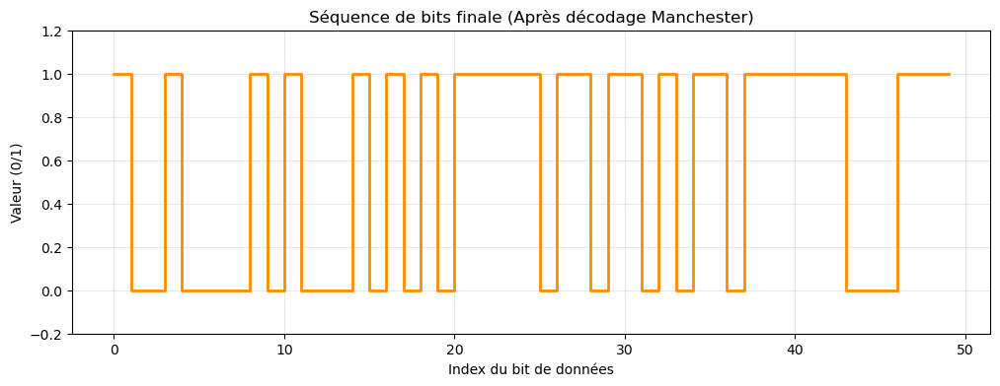

Signal binaire (longueur de 56) :
[1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0]


In [38]:
import numpy as np
import scipy.signal as signal_proc
import matplotlib.pyplot as plt
from IPython.display import Audio

# DÉCODAGE MANCHESTER:
def decode_manchester(bits):
    manchester_bits = []
    # Analyse par paires (Transition)
    for i in range(0, len(bits) - 1, 2):# mettre les bits en pair
        pair = bits[i:i+2]
        if pair == [0, 1]:    # Transition montante du signal renvoi 0
            manchester_bits.append(0)
        elif pair == [1, 0]:  # Transition descendante du signal renvoi 1 
            manchester_bits.append(1)
        # On ignore les erreurs [0,0] ou [1,1] pour la stabilité
    return manchester_bits
    
# Application du décodage: traiter les bits par pair
bits_manchester2 = decode_manchester(bits_extraits)
 
 
 
# Graphique
plt.figure(figsize=(12, 4))
plt.step(range(len(bits_manchester2[:50])), bits_manchester2[:50], where='post', color='darkorange', linewidth=2)
plt.ylim(-0.2, 1.2)
plt.title("Séquence de bits finale (Après décodage Manchester)")
plt.xlabel("Index du bit de données")
plt.ylabel("Valeur (0/1)")
plt.grid(True, alpha=0.3)
plt.show()
print(f"Signal binaire (longueur de {len(bits_manchester2)}) :")
print(bits_manchester2)


## Le message a été chiffré en XOR. Il nous faut donc retrouver la clef de chiffrement 

In [39]:
def find_xor_key_and_decrypt(encrypted_data: bytes):
    print("Tentative de déchiffrement")
    # On ne connaît pas la clé, donc on teste quelques clefs
    for potential_key in range(256):
        test_bytes = bytes(b ^ potential_key for b in encrypted_data)
        try:
            # On cherche une chaîne qui contient des caractères abécédaires
            decoded = test_bytes.decode('utf-8')
            if decoded.isprintable():
                print(f"Clé trouvée: 0x{potential_key:02X} | Message: {decoded}")
        except UnicodeDecodeError:
            continue
            
find_xor_key_and_decrypt(c_back)

Tentative de déchiffrement
Clé trouvée: 0x20 | Message: O}pih<=
Clé trouvée: 0x21 | Message: N|qhi=<
Clé trouvée: 0x23 | Message: L~sjk?>
Clé trouvée: 0x24 | Message: Kytml89
Clé trouvée: 0x25 | Message: Jxulm98
Clé trouvée: 0x26 | Message: I{von:;
Clé trouvée: 0x27 | Message: Hzwno;:
Clé trouvée: 0x28 | Message: Guxa`45
Clé trouvée: 0x29 | Message: Fty`a54
Clé trouvée: 0x2A | Message: Ewzcb67
Clé trouvée: 0x2B | Message: Dv{bc76
Clé trouvée: 0x2C | Message: Cq|ed01
Clé trouvée: 0x2D | Message: Bp}de10
Clé trouvée: 0x2E | Message: As~gf23
Clé trouvée: 0x30 | Message: _m`yx,-
Clé trouvée: 0x31 | Message: ^laxy-,
Clé trouvée: 0x32 | Message: ]ob{z./
Clé trouvée: 0x33 | Message: \ncz{/.
Clé trouvée: 0x34 | Message: [id}|()
Clé trouvée: 0x35 | Message: Zhe|})(
Clé trouvée: 0x38 | Message: Wehqp$%
Clé trouvée: 0x39 | Message: Vdipq%$
Clé trouvée: 0x3A | Message: Ugjsr&'
Clé trouvée: 0x3B | Message: Tfkrs'&
Clé trouvée: 0x3C | Message: Salut !
Clé trouvée: 0x3D | Message: R`mtu! 
Clé trouvée

## Une fois la clef trouvée nous pouvons la désencoder et la déchiffrer

In [40]:
# DESENCODAGE ET DÉCHIFFREMENT :
def manchester_to_utf8(bits, xor_key=0x3C):
    byte_list1 = []
    
    # 1. Regroupement des bits par 8
    for i in range(0, len(bits) - 7, 8):
        octet_bits = bits[i:i+8]
        # Conversion binaire -> entier (0 à 255)
        valeur_octet_chiffre = int("".join(map(str, octet_bits)), 2)
        # ÉTAPE CRUCIALE : Appliquer le XOR pour retrouver l'octet original
        # Sans cette ligne, le UTF-8 ne pourra pas lire le message
        valeur_octet_reel = valeur_octet_chiffre ^ xor_key
        byte_list1.append(valeur_octet_reel)
   
    # Conversion de la liste d'entiers en objet 'bytes'
    donnees_binaires = bytes(byte_list1)
    # Décodage final en UTF-8
    try:
        message_e = donnees_binaires.decode('utf-8', errors='ignore')
        return message_e
    except Exception as e:
        return f"[Erreur de décodage] : {e}"

# Exécution
# On utilise la clé 0x3C qui a été définie au début de ton projet
message_final_envoyé = manchester_to_utf8(bits_back, xor_key=0x3C)

print(f"Octets trouvés : {list(bytes([b ^ 0x3C for b in c_back]))}") # Pour vérification
print(f"Message envoyé    : {message_final_envoyé}")

Octets trouvés : [83, 97, 108, 117, 116, 32, 33]
Message envoyé    : Salut !


## On retrouve bien notre message "Salut !" donc nos signaux sont bons 